<a href="https://colab.research.google.com/github/Malak-Saied/braile/blob/main/04_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Braille Project — Final Evaluation
This notebook evaluates the saved SVM baseline on the held-out test set and optionally evaluates a fine-tuned Wav2Vec2 checkpoint if one is available in Google Drive.
- It does not modify data_prep.py, the preprocessing notebook, the baseline notebook, or the Wav2Vec2 training notebook.
- It uses test.csv only for final evaluation.
- If no trained Wav2Vec2 weights are found, the notebook reports that clearly and skips that model instead of evaluating an untrained classifier.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

%pip -q install librosa soundfile scikit-learn joblib seaborn transformers


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import librosa
import joblib
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2ForSequenceClassification
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

DRIVE = Path('/content/drive/MyDrive')

# Project code/model artifacts are in `braile`; processed CSVs are in `braile-letters`.
PROJECT = DRIVE / 'braile'
DATA_DIR = DRIVE / 'braile-letters' / 'data' / 'processed'
TEST_CSV = DATA_DIR / 'test.csv'
LABELS_JSON = DATA_DIR / 'label2id.json'
SVM_MODEL_PATH = PROJECT / 'models' / 'baseline_svm.joblib'
SVM_CONFIG_PATH = PROJECT / 'models' / 'baseline_config.json'
OUTPUT_DIR = DRIVE / 'braile-letters' / 'evaluation_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for p in [PROJECT / 'data_prep.py', TEST_CSV, LABELS_JSON, SVM_MODEL_PATH, SVM_CONFIG_PATH]:
    print(f'{p}: {p.exists()}')
    assert p.exists(), f'Required file missing: {p}'

sys.path.insert(0, str(PROJECT))
from data_prep import load_audio

test_df = pd.read_csv(TEST_CSV)
label2id = json.loads(LABELS_JSON.read_text())
id2label = {int(v): k for k, v in label2id.items()}

print('\nTest samples:', len(test_df))
print('Classes in label map:', len(label2id))
print('Test columns:', test_df.columns.tolist())
assert {'file_path', 'label', 'label_id'}.issubset(test_df.columns), 'Unexpected test.csv columns'


/content/drive/MyDrive/braile/data_prep.py: True
/content/drive/MyDrive/braile-letters/data/processed/test.csv: True
/content/drive/MyDrive/braile-letters/data/processed/label2id.json: True
/content/drive/MyDrive/braile/models/baseline_svm.joblib: True
/content/drive/MyDrive/braile/models/baseline_config.json: True

Test samples: 216
Classes in label map: 28
Test columns: ['file_path', 'label', 'label_id']


In [10]:
# Resolve audio paths against the original project folder without changing the CSV.
def resolve_audio_path(file_path):
    p = Path(str(file_path))
    candidates = [p] if p.is_absolute() else [PROJECT / p, DRIVE / p]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f'Audio file not found for file_path={file_path!r}. Checked: {candidates}')

# Validate paths before evaluation.
resolved_paths = [resolve_audio_path(p) for p in test_df['file_path']]
print('Audio files found:', len(resolved_paths), '/', len(test_df))
print('Example:', resolved_paths[0])


Audio files found: 216 / 216
Example: /content/drive/MyDrive/braile/data/raw/Cleaned Audio Dataset/Ra/9_Ra_43.wav


1. Evaluate the saved SVM baseline
The feature extraction below matches the final settings saved by 02_baseline.ipynb: MFCCs with n_mfcc=10, n_chunks=5, silence trimming at top_db=25, and the same chunk-mean + overall-standard-deviation pooling. The saved pipeline already includes StandardScaler and SVC.

In [11]:
baseline = joblib.load(SVM_MODEL_PATH)
BEST = json.loads(SVM_CONFIG_PATH.read_text())
print('Saved SVM configuration:', BEST)

def mfcc_matrix_from_audio_path(path, n_mfcc, top_db=25):
    audio, sr = load_audio(str(path))
    audio, _ = librosa.effects.trim(audio, top_db=top_db)
    if len(audio) < 4096:
        audio = np.pad(audio, (0, 4096 - len(audio)))
    return librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc)

def pool_mfcc(m, n_chunks):
    chunks = np.array_split(m, n_chunks, axis=1)
    return np.concatenate([chunk.mean(axis=1) for chunk in chunks] + [m.std(axis=1)])

X_test = np.stack([
    pool_mfcc(mfcc_matrix_from_audio_path(path, BEST['n_mfcc']), BEST['n_chunks'])
    for path in resolved_paths
])
y_test = test_df['label_id'].astype(int).to_numpy()
svm_pred = baseline.predict(X_test)

svm_metrics = {
    'Model': 'SVM baseline',
    'Accuracy': accuracy_score(y_test, svm_pred),
    'Macro Precision': precision_score(y_test, svm_pred, average='macro', zero_division=0),
    'Macro Recall': recall_score(y_test, svm_pred, average='macro', zero_division=0),
    'Macro-F1': f1_score(y_test, svm_pred, average='macro', zero_division=0),
}
print('Test feature shape:', X_test.shape)
display(pd.DataFrame([svm_metrics]).round(4))


Saved SVM configuration: {'n_mfcc': 10, 'n_chunks': 5, 'C': 10}
Test feature shape: (216, 60)


,Model,Accuracy,Macro Precision,Macro Recall,Macro-F1
0,SVM baseline,0.7731,0.8084,0.776,0.7855


              precision    recall  f1-score   support

        Alif     1.0000    0.9167    0.9565        12
          Ba     1.0000    0.8889    0.9412         9
          Ta     0.8000    0.8000    0.8000        10
        Thaa     0.0000    0.0000    0.0000         7
        Jeem     0.8750    1.0000    0.9333         7
          Ha     1.0000    1.0000    1.0000         8
         Kha     1.0000    0.8571    0.9231         7
         Dal     0.5000    0.3333    0.4000         6
        Thal     0.3182    0.5000    0.3889        14
          Ra     0.7273    1.0000    0.8421         8
         Zay     1.0000    0.7778    0.8750         9
        Seen     0.8000    0.8000    0.8000         5
       Sheen     0.8000    0.8000    0.8000         5
         Sad     1.0000    0.8333    0.9091         6
         Dad     0.8333    0.8333    0.8333         6
         Taa     0.6000    0.6667    0.6316         9
         Zaa     0.5714    0.5714    0.5714         7
         Ain     0.7778    

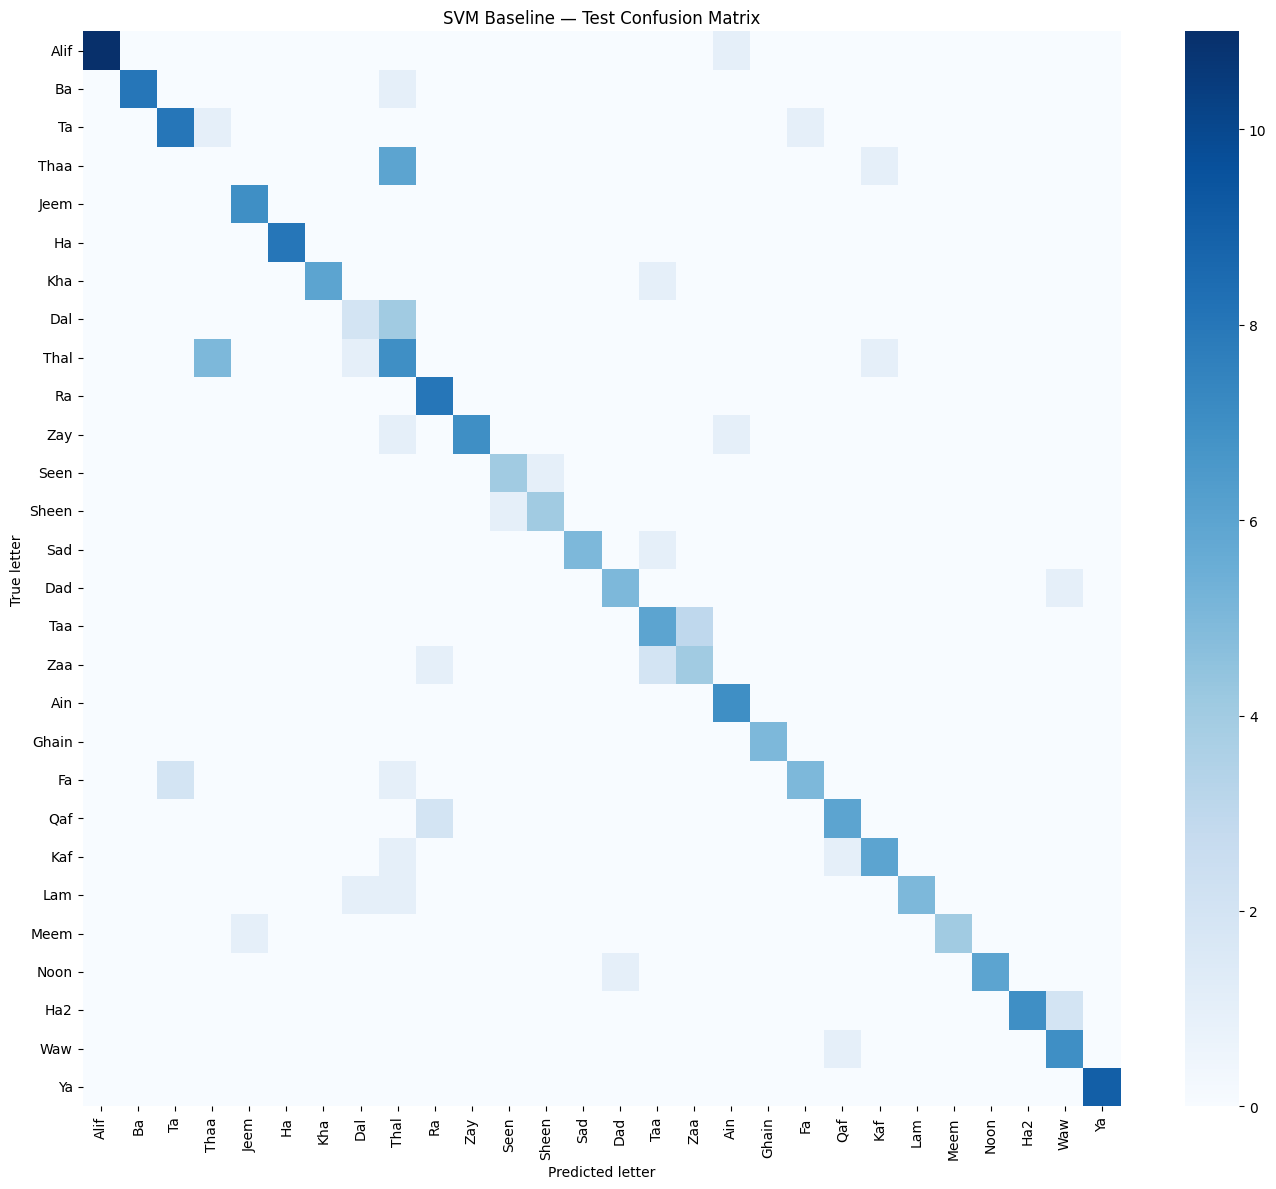

Saved: /content/drive/MyDrive/braile-letters/evaluation_results/svm_test_predictions.csv


In [12]:
# Per-class report and confusion matrix for SVM
class_ids = sorted(set(test_df['label_id'].astype(int)))
class_names = [id2label[i] for i in class_ids]

print(classification_report(
    y_test, svm_pred,
    labels=class_ids,
    target_names=class_names,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(y_test, svm_pred, labels=class_ids)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted letter')
plt.ylabel('True letter')
plt.title('SVM Baseline — Test Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

svm_results = test_df[['file_path', 'label', 'label_id']].copy()
svm_results['prediction_id'] = svm_pred
svm_results['prediction'] = [id2label[int(i)] for i in svm_pred]
svm_results['correct'] = svm_results['label_id'].astype(int) == svm_results['prediction_id']
svm_results.to_csv(OUTPUT_DIR / 'svm_test_predictions.csv', index=False)
print('Saved:', OUTPUT_DIR / 'svm_test_predictions.csv')


2. Find and evaluate a trained Wav2Vec2 checkpoint (optional)
The original 03_wav2vec2 notebook loads pretrained Wav2Vec2 with a new, untrained classification head, and its last cell only trains on 48 samples for 1 epoch as a smoke test. Do not treat that as the final trained model. This section searches common Drive locations for a checkpoint containing model weights. It skips Wav2Vec2 if no saved weights are found.

In [13]:
# Search likely folders for a fine-tuned checkpoint.
search_roots = [
    DRIVE / 'braile-letters',
    DRIVE / 'braile',
    DRIVE / 'w2v_base_30',
    DRIVE / 'w2v_base',
    DRIVE / 'w2v_xlsr',
    DRIVE / 'wav2vec2_evaluation',
]
weight_names = {'model.safetensors', 'pytorch_model.bin', 'pytorch_model.pt'}
candidate_dirs = []
for root in search_roots:
    if root.exists():
        for config in root.rglob('config.json'):
            folder = config.parent
            if any((folder / name).exists() for name in weight_names):
                candidate_dirs.append(folder)

# De-duplicate while preserving order
candidate_dirs = list(dict.fromkeys(candidate_dirs))
print('Checkpoint directories with model weights:')
for p in candidate_dirs[:30]:
    print(' -', p)
if not candidate_dirs:
    print('No Wav2Vec2 checkpoint weights found. Wav2Vec2 evaluation will be skipped.')


Checkpoint directories with model weights:
No Wav2Vec2 checkpoint weights found. Wav2Vec2 evaluation will be skipped.


In [14]:
w2v_metrics = None
w2v_results = None

if candidate_dirs:
    # Prefer an explicitly named fine-tuned checkpoint; otherwise use the first checkpoint found.
    preferred = [p for p in candidate_dirs if any(k in str(p).lower() for k in ['checkpoint', 'fine', 'trained', 'wav2vec2'])]
    W2V_DIR = preferred[0] if preferred else candidate_dirs[0]
    print('Using checkpoint:', W2V_DIR)

    fe = Wav2Vec2FeatureExtractor.from_pretrained(str(W2V_DIR))
    w2v_model = Wav2Vec2ForSequenceClassification.from_pretrained(str(W2V_DIR))
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    w2v_model = w2v_model.to(device).eval()

    # Verify model output dimension aligns with the project's class mapping.
    num_model_labels = int(w2v_model.config.num_labels)
    if num_model_labels != len(label2id):
        raise ValueError(
            f'Checkpoint has {num_model_labels} output labels but label2id has {len(label2id)} classes. '
            'Check that this is the fine-tuned checkpoint for this dataset.'
        )

    w2v_preds = []
    batch_size = 8
    with torch.no_grad():
        for start in range(0, len(resolved_paths), batch_size):
            batch_paths = resolved_paths[start:start + batch_size]
            batch_audio = [load_audio(str(p))[0] for p in batch_paths]
            encoded = fe(batch_audio, sampling_rate=16000, padding=True, return_tensors='pt')
            logits = w2v_model(encoded.input_values.to(device)).logits
            w2v_preds.extend(logits.argmax(dim=-1).cpu().numpy().tolist())

    w2v_pred = np.asarray(w2v_preds, dtype=int)
    w2v_metrics = {
        'Model': f'Wav2Vec2 ({W2V_DIR.name})',
        'Accuracy': accuracy_score(y_test, w2v_pred),
        'Macro Precision': precision_score(y_test, w2v_pred, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, w2v_pred, average='macro', zero_division=0),
        'Macro-F1': f1_score(y_test, w2v_pred, average='macro', zero_division=0),
    }
    display(pd.DataFrame([w2v_metrics]).round(4))

    w2v_results = test_df[['file_path', 'label', 'label_id']].copy()
    w2v_results['prediction_id'] = w2v_pred
    w2v_results['prediction'] = [id2label[int(i)] for i in w2v_pred]
    w2v_results['correct'] = w2v_results['label_id'].astype(int) == w2v_results['prediction_id']
    w2v_results.to_csv(OUTPUT_DIR / 'wav2vec2_test_predictions.csv', index=False)
    print('Saved:', OUTPUT_DIR / 'wav2vec2_test_predictions.csv')


In [15]:
# Final metric comparison and export
summary_rows = [svm_metrics]
if w2v_metrics is not None:
    summary_rows.append(w2v_metrics)

summary = pd.DataFrame(summary_rows)
display(summary.round(4))
summary.to_csv(OUTPUT_DIR / 'final_model_comparison.csv', index=False)
print('Saved:', OUTPUT_DIR / 'final_model_comparison.csv')

print('\nEvaluation output folder:', OUTPUT_DIR)
print('Files:', [p.name for p in OUTPUT_DIR.iterdir() if p.is_file()])


,Model,Accuracy,Macro Precision,Macro Recall,Macro-F1
0,SVM baseline,0.7731,0.8084,0.776,0.7855


Saved: /content/drive/MyDrive/braile-letters/evaluation_results/final_model_comparison.csv

Evaluation output folder: /content/drive/MyDrive/braile-letters/evaluation_results
Files: ['svm_test_predictions.csv', 'final_model_comparison.csv']
